In [34]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 

In [6]:

df = pd.read_csv("~/Downloads/exoplanet_data.csv", comment = '#')

In [7]:
df.shape

(599, 92)

In [15]:
print(df.columns)

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [ ]:
#st_logerr2, st_met, sy_gaiama, pl_pubdat, pl_radjerr2


In [ ]:
#pl_name, hostname, discoverymethod, st_spectype, pl_eqt, pl_massj

In [17]:
dfs = df[["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]]

In [19]:
dat = dfs.dropna()

In [20]:
dat.shape

(77, 6)

In [22]:
dat.head()
dat.tail()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


In [24]:
dat.columns

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')

In [30]:
df.value_counts("discoverymethod")

discoverymethod
Transit                      405
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64

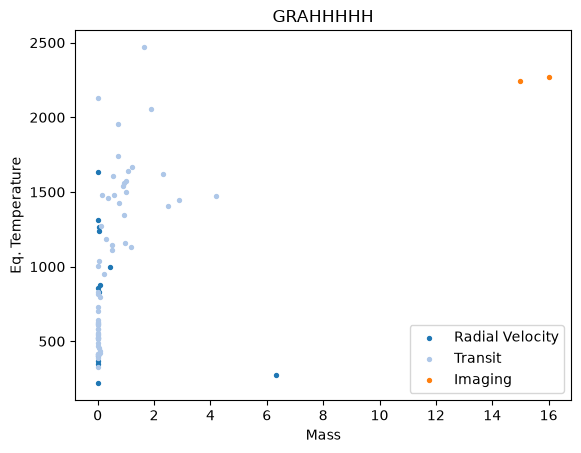

In [48]:
fig, axes = plt.subplots(1,1)
methods = dat["discoverymethod"].unique()
colors = plt.cm.tab20(range(len(methods)))
for method, color in zip(methods, colors):
    group = dat[dat["discoverymethod"] == method]
    axes.scatter(group["pl_bmassj"], group["pl_eqt"], s=8, color=color, label=method)
axes.set_xlabel("Mass")
axes.set_ylabel("Eq. Temperature")
axes.set_title("GRAHHHHH")
axes.legend()
plt.show()

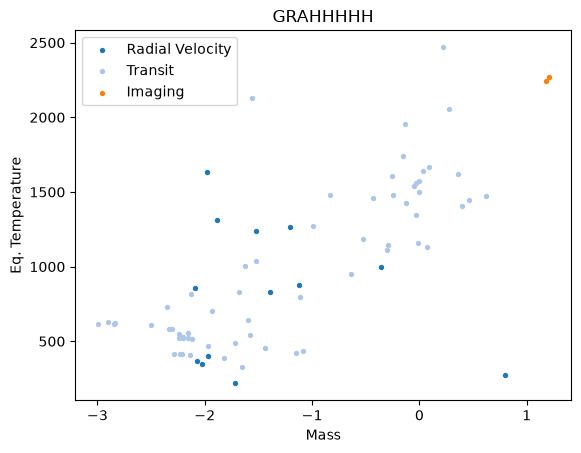

In [50]:
fig, axes = plt.subplots(1,1)
methods = dat["discoverymethod"].unique()
colors = plt.cm.tab20(range(len(methods)))
for method, color in zip(methods, colors):
    group = dat[dat["discoverymethod"] == method]
    axes.scatter(np.log10(group["pl_bmassj"]), group["pl_eqt"], s=8, color=color, label=method)
axes.set_xlabel("Mass")
axes.set_ylabel("Eq. Temperature")
axes.set_title("GRAHHHHH")
axes.legend()
plt.show()

In [ ]:
# Likely to be massive 


In [55]:
print(dat[(dat["pl_eqt"] < 500) & (dat["pl_bmassj"] > 1)])

         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0       6.31


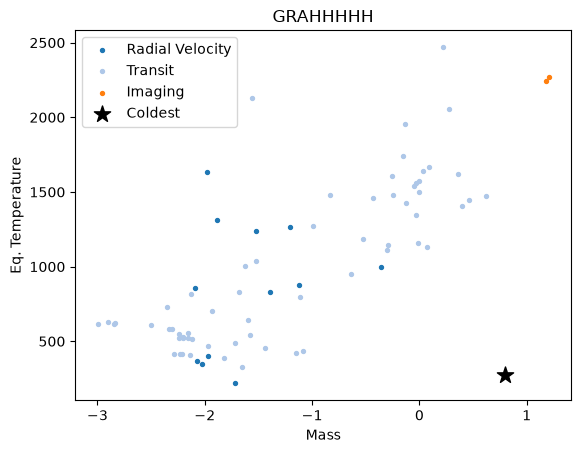

In [63]:
coldest = dat[(dat["pl_eqt"] < 500) & (dat["pl_bmassj"] > 1)]
fig, axes = plt.subplots(1,1)
methods = dat["discoverymethod"].unique()
colors = plt.cm.tab20(range(len(methods)))
for method, color in zip(methods, colors):
    group = dat[dat["discoverymethod"] == method]
    axes.scatter(np.log10(group["pl_bmassj"]), group["pl_eqt"], s=8, color=color, label=method)
axes.scatter(np.log10(coldest["pl_bmassj"]), coldest["pl_eqt"],
             s=150, color="black", marker="*", label="Coldest")
axes.set_xlabel("Mass")
axes.set_ylabel("Eq. Temperature")
axes.set_title("GRAHHHHH")
axes.legend()
plt.show()

In [ ]:
!git branc